# Tinjauan model kategori material

Notebook pendamping EDA utama. Semua nama kelas di sini merupakan **prediksi algoritmis**, belum label benar terverifikasi. Delapan folder memastikan setiap citra mempunyai keluaran; hal itu tidak membuktikan kemurnian kelas atau Accuracy sempurna.

Notebook ini meninjau hasil checkpoint yang sudah dilatih dan dibekukan, bukan mengulang training. Artefak lokal, dataset resmi, serta lingkungan pada requirements diperlukan. Tidak ada panggilan LLM/VLM atau layanan prediksi eksternal. Model awal non-VLM, adaptasi lokal, dan sumber bobot dijelaskan pada laporan eksperimen. Kontrak label aktif belum dipromosikan.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / 'configs/data_contract.json').exists())
common = ROOT / 'reports/errors/stage6_material_resolution_20261106'
selection = json.loads((common / 'selected_material_run.json').read_text())
source = ROOT / selection['output']
report = ROOT / selection['report']
frozen = json.loads((report / 'selection_frozen.json').read_text())
assignment = source / 'named_assignments.csv'
assert hashlib.sha256(assignment.read_bytes()).hexdigest() == frozen['assignment_sha256']
predictions = pd.read_csv(assignment, dtype={'image_id': str})
classes = ['glass', 'paper', 'electronic', 'metal', 'plastic', 'cardboard', 'textile', 'foodwaste']
assert len(predictions) == 2400 and predictions.key.is_unique
assert predictions.predicted_class.isin(classes).all()
assert not predictions.ground_truth_verified.any()
print('Model:', selection['output'])
print('Train:', (predictions.split == 'train').sum(), '| Test:', (predictions.split == 'test').sum())
display(pd.Series(json.loads((report / 'summary.json').read_text())['selected'], name='pemilihan model tanpa label resmi'))

Model: output\groups\stage17_hierarchical_routing_v1
Train: 1920 | Test: 480


candidate                                        fixed_hierarchical_routing
macro_anchor_agreement                                             0.985841
flip                                                                    1.0
routed_train                                                            570
routing_groups                                                       [2, 6]
note                      Structural hypothesis, not a new proxy-score w...
Name: pemilihan model tanpa label resmi, dtype: object

## Distribusi prediksi dan tanda tinjau

Jumlah per kelas adalah keluaran model, bukan kuota yang dipaksakan. Probabilitas softmax belum dikalibrasi. Tanda `needs_review` mencakup keyakinan rendah, margin kecil, atau konflik dengan salah satu sumber CNN; konflik juga dapat berasal dari kekeliruan sumber tersebut.

split,test,train
predicted_class,,
glass,57,204
paper,47,243
electronic,60,208
metal,65,250
plastic,60,276
cardboard,57,247
textile,68,225
foodwaste,66,267


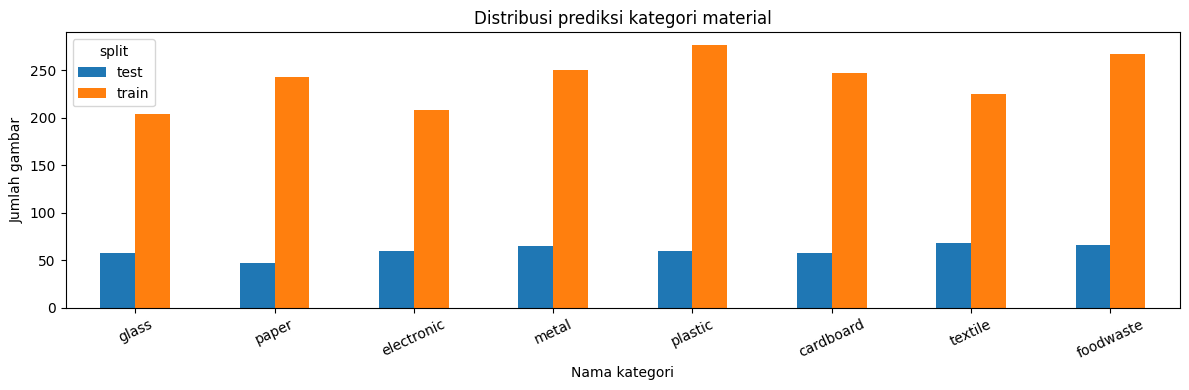

,gambar,perlu_tinjau,keyakinan_atau_margin_rendah,konflik_sumber_saja
split,,,,
test,480,126,25,101
train,1920,570,126,444


Tanda tinjau bukan ukuran kelompok campuran atau jumlah salah. Konflik sumber saja dapat berasal dari CNN pembanding yang keliru.
Accuracy semantik: belum dapat diukur tanpa label evaluasi independen.


In [2]:
counts = pd.crosstab(predictions.predicted_class, predictions.split).reindex(classes, fill_value=0)
display(counts)
axes = counts.plot.bar(figsize=(12, 4), rot=25, title='Distribusi prediksi kategori material')
axes.set_ylabel('Jumlah gambar'); axes.set_xlabel('Nama kategori'); plt.tight_layout(); plt.show()
predictions['keyakinan_atau_margin_rendah'] = predictions.uncalibrated_probability.lt(.65) | predictions.margin.lt(.25)
predictions['konflik_sumber_saja'] = predictions.cnn_prior_disagrees & ~predictions.keyakinan_atau_margin_rendah
review = predictions.groupby('split').agg(gambar=('key', 'size'), perlu_tinjau=('needs_review', 'sum'), keyakinan_atau_margin_rendah=('keyakinan_atau_margin_rendah', 'sum'), konflik_sumber_saja=('konflik_sumber_saja', 'sum'))
display(review)
print('Tanda tinjau bukan ukuran kelompok campuran atau jumlah salah. Konflik sumber saja dapat berasal dari CNN pembanding yang keliru.')
print('Accuracy semantik: belum dapat diukur tanpa label evaluasi independen.')

## Preview seluruh kategori: train dan test

Contoh dipilih secara deterministik dari prediksi bermargin tinggi pada setiap kategori. Pemilihan contoh ini membantu membaca keluaran, bukan mengonfirmasi semua anggota kelas benar.

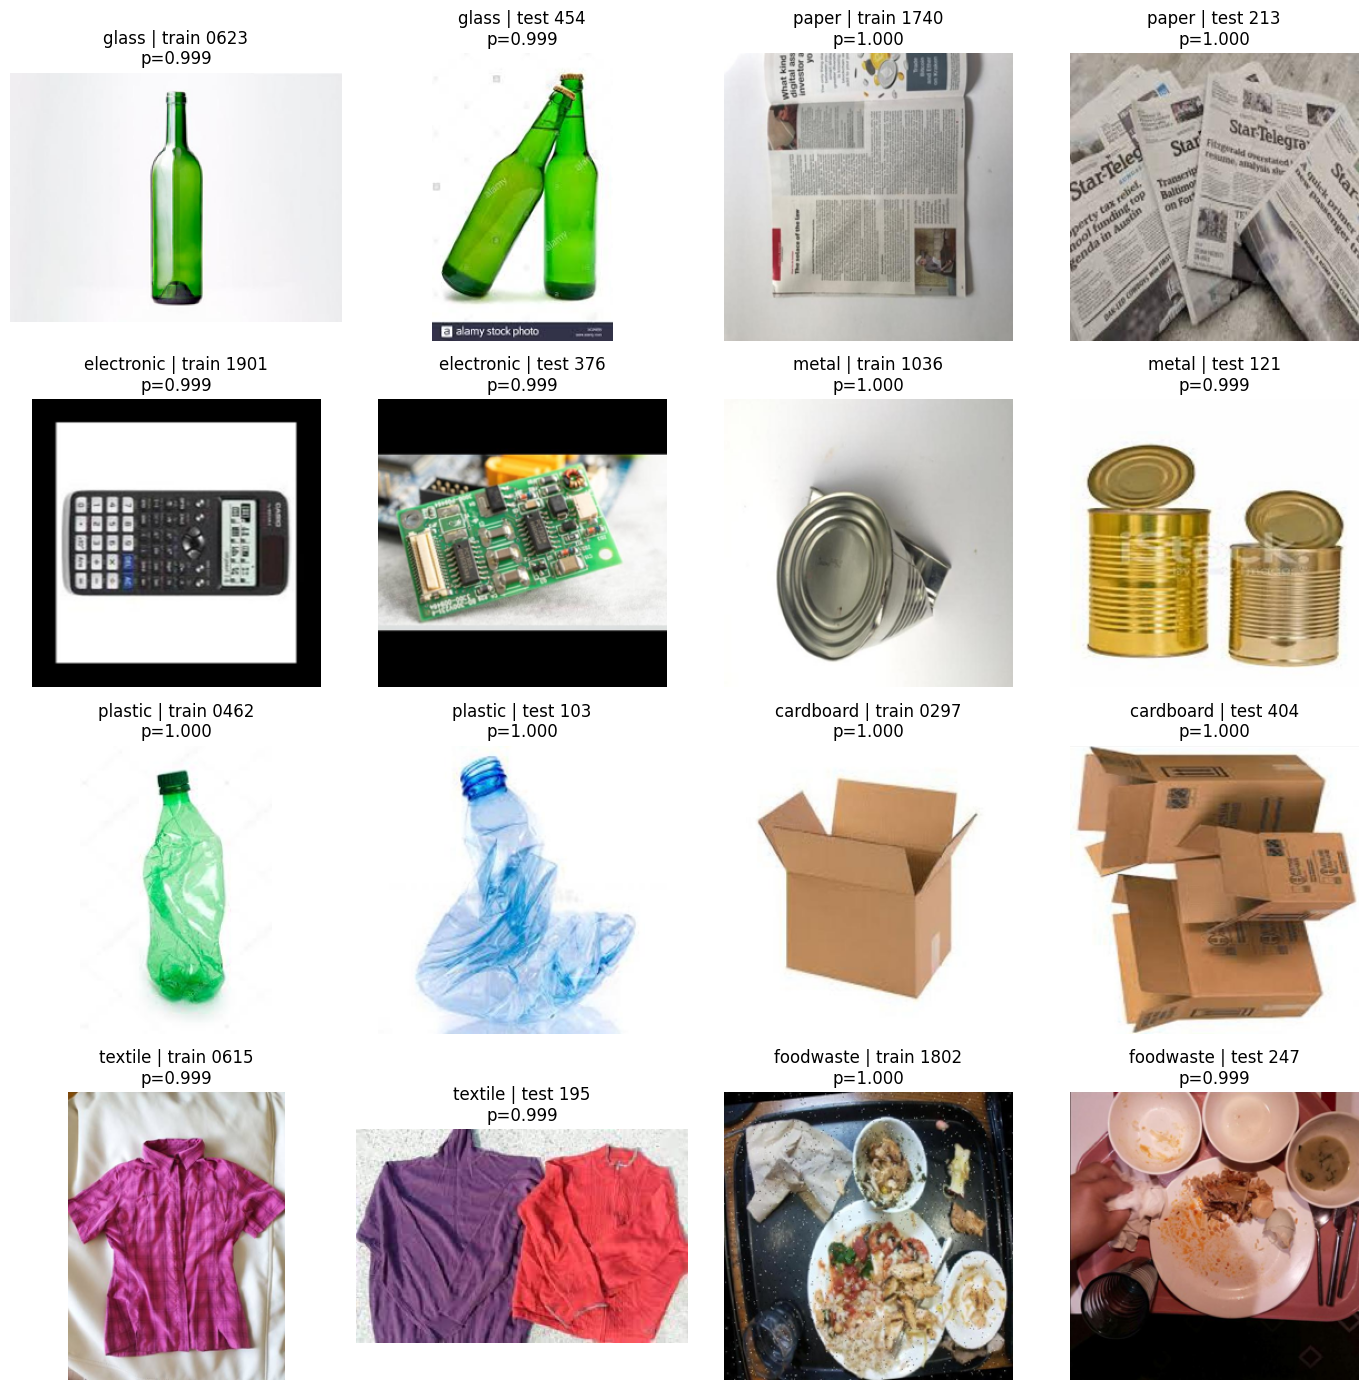

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for c, name in enumerate(classes):
    for offset, split in enumerate(['train', 'test']):
        ax = axes.flat[2*c+offset]
        rows = predictions[(predictions.split == split) & (predictions.predicted_class == name)].sort_values(['margin', 'key'], ascending=[False, True])
        if len(rows):
            row = rows.iloc[0]
            with Image.open(ROOT / row.processed_path) as image:
                image = image.convert('RGB'); image.thumbnail((260, 260)); ax.imshow(image)
            ax.set_title(f'{name} | {split} {row.image_id}\np={row.uncalibrated_probability:.3f}')
        else: ax.set_title(f'{name} | {split}: tidak ada prediksi')
        ax.axis('off')
plt.tight_layout(); plt.show()

## Contoh yang masih memerlukan tinjau

Prioritaskan test yang ditandai dan margin terkecil. Gambar tetap dipertahankan; tidak dihapus atau dipindah secara manual. Objek yang berdekatan, bahan transparan dan tekstur kemasan dapat menyebabkan konflik. Kandidat crop dan kemiripan piksel lebih rinci tersedia pada notebook EDA utama.

,key,predicted_class,uncalibrated_probability,margin,cnn_prior_disagrees
1827,train:1828,textile,0.484991,0.001823,False
1912,train:1913,paper,0.411004,0.013222,True
1600,train:1601,foodwaste,0.288402,0.016474,True
4,train:0005,metal,0.452824,0.018718,True
944,train:0945,electronic,0.353674,0.019108,True
713,train:0714,glass,0.499574,0.020938,True
1168,train:1169,electronic,0.322751,0.024757,True
1092,train:1093,textile,0.362063,0.026131,True
1862,train:1863,paper,0.296920,0.026915,True
991,train:0992,cardboard,0.354974,0.036709,True


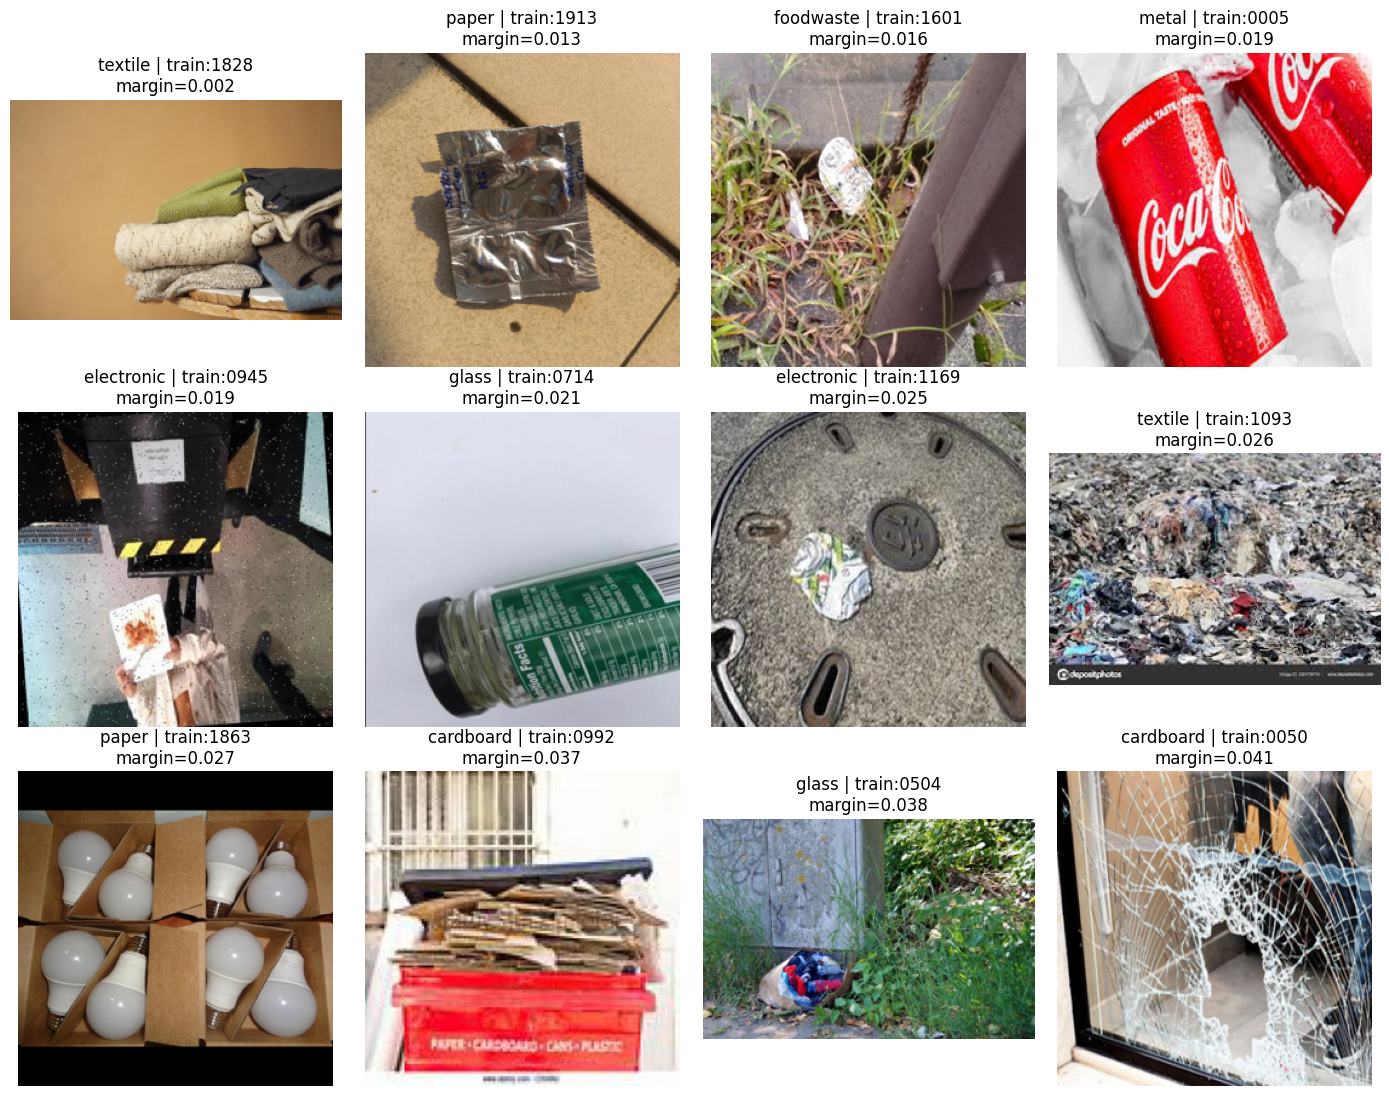

Data asli dipertahankan. Prediksi dan tanda tinjau tersimpan pada manifest terpisah.


In [4]:
queue = predictions[predictions.needs_review].sort_values(['split', 'margin', 'key'], ascending=[False, True, True]).head(12)
display(queue[['key', 'predicted_class', 'uncalibrated_probability', 'margin', 'cnn_prior_disagrees']])
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax in axes.flat: ax.axis('off')
for ax, row in zip(axes.flat, queue.itertuples()):
    with Image.open(ROOT / row.processed_path) as image:
        image = image.convert('RGB'); image.thumbnail((260, 260)); ax.imshow(image)
    ax.set_title(f'{row.predicted_class} | {row.key}\nmargin={row.margin:.3f}')
plt.tight_layout(); plt.show()
print('Data asli dipertahankan. Prediksi dan tanda tinjau tersimpan pada manifest terpisah.')